# Stellar Spectra

https://www.eso.org/sci/facilities/paranal/decommissioned/isaac/tools/lib.html

**Do the FWHM of H alpha, beta and gamma as a function of temperature. (For sure alpha)**

**Fit also the Lorentz profile** 

## Exercise 1
We are using for this exercise the Specrtal type B and the roman number III

**file name:** ukb3iii.dat


In [15]:
import numpy as np

data = np.loadtxt('ukb3iii.dat')

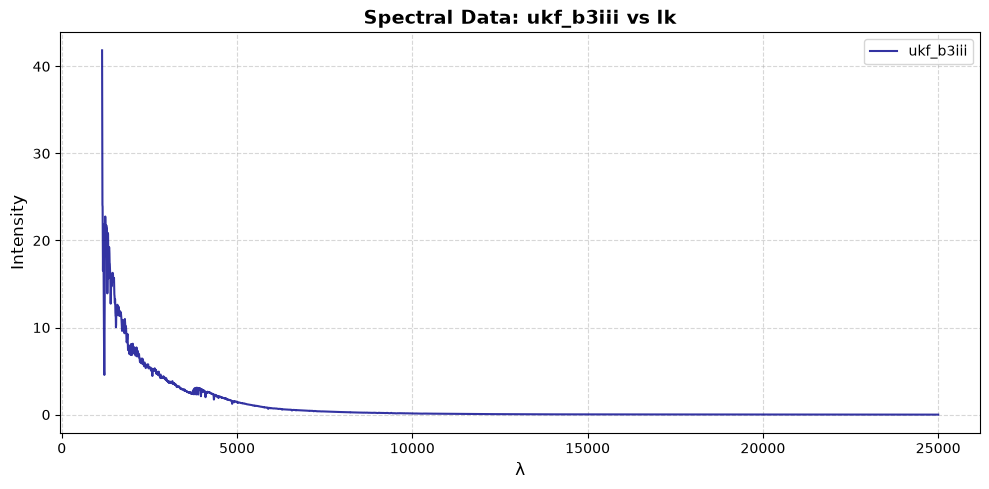

In [16]:
import matplotlib.pyplot as plt

# 1. Cargar las dos primeras columnas ignorando los encabezados con '#'
# usecols=(0, 1) selecciona la primera columna (lk) y la segunda (ukf_b3iii)
x, y = np.loadtxt("ukb3iii.dat", comments="#", usecols=(0, 1), unpack=True)


plt.figure(figsize=(10, 5))
plt.plot(x, y, linestyle="-", color="darkblue", alpha=0.8, label="ukf_b3iii")


plt.title("Spectral Data: ukf_b3iii vs lk", fontsize=14, fontweight="bold")
plt.xlabel("λ", fontsize=12)
plt.ylabel("Intensity", fontsize=12)


plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()

plt.show()


#### This we have to fit to the Black Body 

The equation of Black body is:  

$${\displaystyle B_{\lambda }(\lambda ,T)={\frac {2hc^{2}}{\lambda ^{5}}}{\frac {1}{\exp \left({\frac {hc}{\lambda k_{\mathrm {B} }T}}\right)-1}}}$$

Keep the values consistent, and also the exponential has to be dimentionless. Also, be careful with the units. 

Queremos ajustar:

$I_\lambda=A\,B_\lambda(\lambda,T)$

* T: temperatura que determina la forma de la curva.
* A: constante que ajusta su altura.
* Initial guess: una temperatura aproximada para comenzar el ajuste.

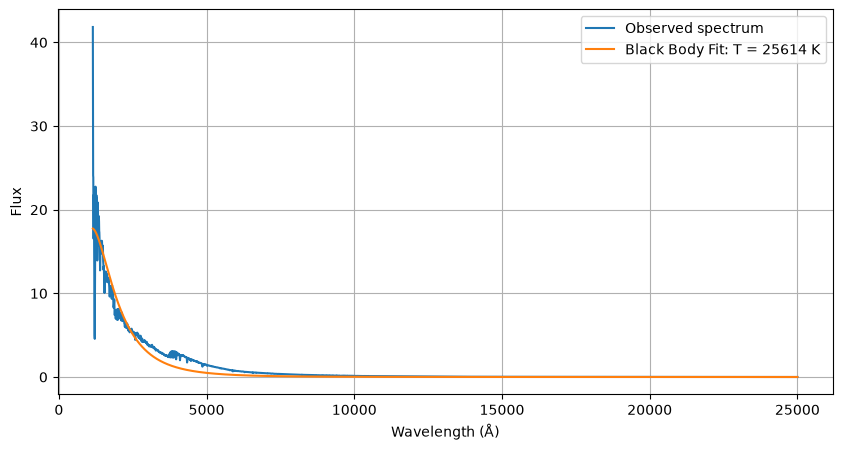

Temperature = 25614 K


In [20]:
from scipy.constants import h, c, k
from scipy.optimize import curve_fit

#Planck Function
def planck(lam, T):
    lam = lam * 1e-10
    return (2*h*c**2 / lam**5) / np.exp(h*c / (lam*k*T)-1)

# Black Body Model
def blackbody(lam, T, A):
    return A * planck(lam, T)

# Initial Guesses
T0 = 18000
A0 = np.max(y) / np.max(planck(x, T0))

# Black Body Fitting
params, covariance = curve_fit(
    blackbody, x, y,
    p0=[T0, A0],
    bounds=([1000, 0], [100000, np.inf]),
    maxfev=20000
)

T_fit, A_fit = params

# Plot Observed Spectrum and Black Body Fit
plt.figure(figsize=(10, 5))
plt.plot(x, y, label="Observed spectrum")
plt.plot(x, blackbody(x, T_fit, A_fit),
         label=f"Black Body Fit: T = {T_fit:.0f} K")

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.legend()
plt.grid()
plt.show()

# Best-Fit Temperature
print(f"Temperature = {T_fit:.0f} K")

**Next we have to**:

– Do the FWHM of H alpha, beta and gamma as a function of temperature. (For sure alpha)

– Fit also the Lorentz profile

## Exercise 2

We are using for this one **ukg5iii.dat

In [22]:
import numpy as np

data = np.loadtxt('ukg5iii.dat')

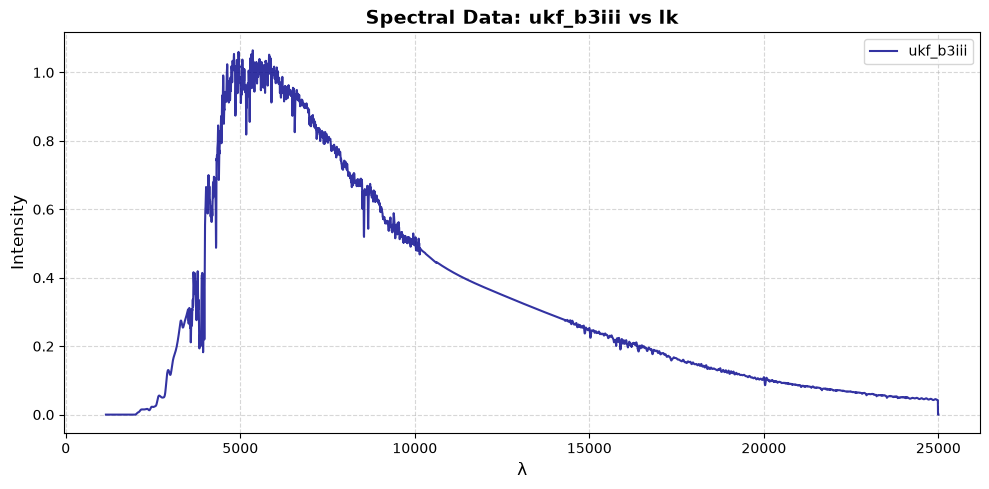

In [23]:
import matplotlib.pyplot as plt

x, y = np.loadtxt("ukg5iii.dat", comments="#", usecols=(0, 1), unpack=True)

plt.figure(figsize=(10, 5))
plt.plot(x, y, linestyle="-", color="darkblue", alpha=0.8, label="ukf_b3iii")

plt.title("Spectral Data: ukf_b3iii vs lk", fontsize=14, fontweight="bold")
plt.xlabel("λ", fontsize=12)
plt.ylabel("Intensity", fontsize=12)

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()

plt.show()


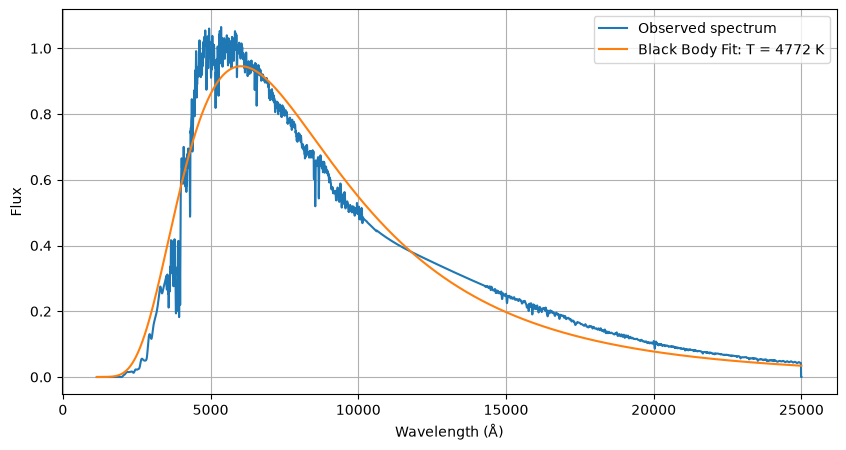

Temperature = 4772 K


In [24]:
from scipy.constants import h, c, k
from scipy.optimize import curve_fit

# Planck function
def planck(lam, T):
    lam = lam * 1e-10  
    return (2*h*c**2 / lam**5) / np.exp(h*c / (lam*k*T)-1)

# Black body model
def blackbody(lam, T, A):
    return A * planck(lam, T)

# Initial guess
T0 = 18000
A0 = np.max(y) / np.max(planck(x, T0)) 

# Fit
params, covariance = curve_fit(
    blackbody, x, y,
    p0=[T0, A0],
    bounds=([1000, 0], [100000, np.inf]),
    maxfev=20000
)

T_fit, A_fit = params

# Plot
plt.figure(figsize=(10, 5))
plt.plot(x, y, label="Observed spectrum")
plt.plot(x, blackbody(x, T_fit, A_fit),
         label=f"Black Body Fit: T = {T_fit:.0f} K")

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.legend()
plt.grid()
plt.show()

print(f"Temperature = {T_fit:.0f} K")

# Codes explained

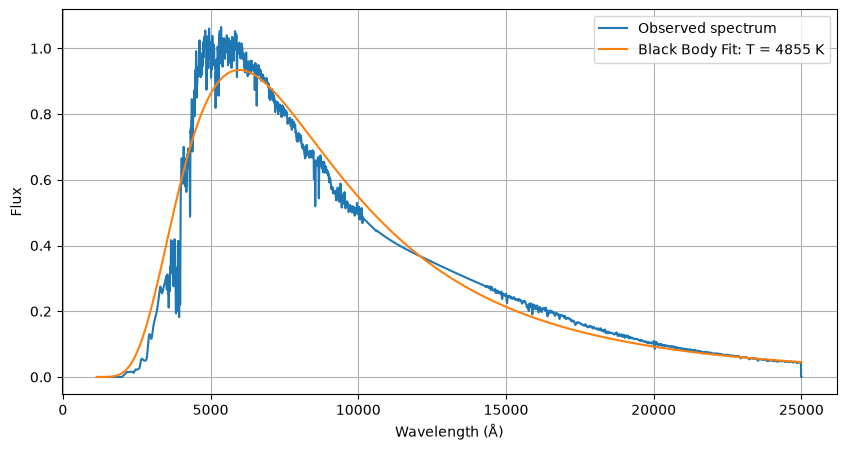

Temperature = 4855 K


In [25]:
from scipy.constants import h, c, k
from scipy.optimize import curve_fit

# 1. Planck function
# Calculates the spectral radiance of a black body at a given wavelength and temperature.
def planck(lam, T):
    # Convert wavelength from Angstroms to meters (SI units).
    lam = lam * 1e-10

    # Apply Planck's law.
    # np.expm1(x) is equivalent to exp(x) - 1, but more numerically accurate.
    return (2*h*c**2 / lam**5) / np.expm1(h*c / (lam*k*T))


# 2. Black body model
# Multiply Planck's function by a scaling constant A.
# A adjusts the amplitude of the curve to match the observed spectrum.
def blackbody(lam, T, A):
    return A * planck(lam, T)


# 3. Initial guesses
# Provide starting values for the fitting algorithm.
T0 = 18000  # Initial temperature guess in Kelvin (K).

# Estimate the initial scaling constant by comparing the maximum observed
# intensity with the maximum intensity predicted by Planck's function.
A0 = np.max(y) / np.max(planck(x, T0))


# 4. Fit the black body model to the observed spectrum
# curve_fit finds the values of T and A that minimize the squared
# differences between the observed data and the theoretical model.
params, covariance = curve_fit(
    blackbody, x, y,
    p0=[T0, A0],                         # Initial guesses for T and A.
    bounds=([1000, 0], [100000, np.inf]), # Allowed parameter ranges.
    maxfev=20000                        # Maximum number of function evaluations.
)

# Extract the best-fit temperature and scaling constant.
T_fit, A_fit = params


# 5. Plot the results
plt.figure(figsize=(10, 5))

# Plot the observed spectrum.
plt.plot(x, y, label="Observed spectrum")

# Plot the theoretical black body curve using the fitted parameters.
plt.plot(x, blackbody(x, T_fit, A_fit),
         label=f"Black Body Fit: T = {T_fit:.0f} K")

# Add labels, legend, and grid.
plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.legend()
plt.grid()
plt.show()


# 6. Display the fitted temperature
print(f"Temperature = {T_fit:.0f} K")